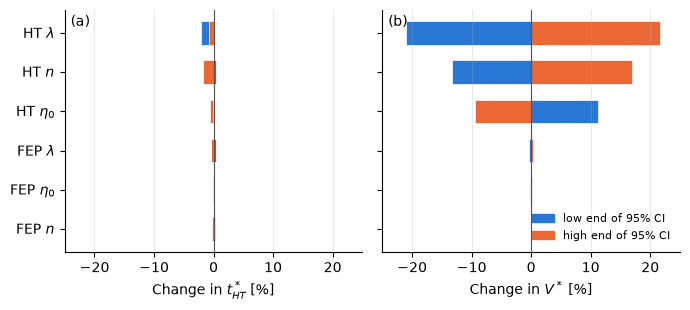

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Baseline design at 330 C with HT Ea = 92.4 kJ/mol (full precision, not the rounded printout).
# If you run this in the same notebook as the sweep, delete this line and the sweep's t0, V0 are used.
t0, V0 = 0.028512, 0.056809

oat = pd.read_csv("sensitivity_oat.csv")

# % change from baseline for each run
oat["dt_pct"] = 100 * (oat["t_HT [mm]"] - t0) / t0
oat["dV_pct"] = 100 * (oat["V* [m/s]"] - V0) / V0

# Labels in the report's notation (the code's m is the report's n)
names = {"eta0": r"$\eta_0$", "lam": r"$\lambda$", "m": r"$n$"}
oat["label"] = oat["polymer"] + " " + oat["param"].map(names)

# One row per parameter, low and high side by side
wide = oat.pivot(index="label", columns="end", values=["dt_pct", "dV_pct"])

# Sort by how much V* swings (biggest at the top of the plot)
swing = (wide[("dV_pct", "high")] - wide[("dV_pct", "low")]).abs()
wide = wide.loc[swing.sort_values().index]

LOW, HIGH = "#2a78d6", "#eb6834"   # blue = low end of CI, orange = high end
y = range(len(wide))

fig, axes = plt.subplots(1, 2, figsize=(7, 3.2), sharey=True)
for ax, col, xlabel, tag in [(axes[0], "dt_pct", r"Change in $t^*_{HT}$ [%]", "(a)"),
                             (axes[1], "dV_pct", r"Change in $V^*$ [%]", "(b)")]:
    lo, hi = wide[(col, "low")].values, wide[(col, "high")].values
    for i in y:
        # draw the longer bar first so a shorter bar on the same side stays visible
        for v, c in sorted([(lo[i], LOW), (hi[i], HIGH)], key=lambda p: -abs(p[0])):
            ax.barh(i, v, color=c, height=0.6, edgecolor="white", linewidth=0.5)
    ax.axvline(0, color="#52514e", lw=0.8)
    ax.set_xlabel(xlabel)
    ax.set_xlim(-25, 25)                 # same scale on both panels so they compare fairly
    ax.grid(axis="x", alpha=0.25)
    ax.text(0.02, 0.98, tag, transform=ax.transAxes, va="top")
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

axes[0].set_yticks(list(y))
axes[0].set_yticklabels(wide.index)
axes[1].legend(handles=[Patch(color=LOW, label="low end of 95% CI"),
                        Patch(color=HIGH, label="high end of 95% CI")],
               loc="lower right", frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig("sensitivity_tornado.png", dpi=300, bbox_inches="tight")
fig.savefig("sensitivity_tornado.pdf", bbox_inches="tight")
plt.show()